Importing libraries

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

Loading datasets

In [ ]:
# historical tournament matchups
men = pd.read_csv("../data/processed/men_massey.csv")
women = pd.read_csv("../data/processed/women_processed.csv")
# Elo ratings for each team at the end of each season
men_elo = pd.read_csv("../data/processed/men_elo.csv")
women_elo = pd.read_csv("../data/processed/women_elo.csv")

print("Men's matchups:", men.shape)
print("Women's matchups:", women.shape)
print("Men's Elo data:", men_elo.shape)
print("Women's Elo data:", women_elo.shape)

,Season,Team1,Team2,SeedDiff,AvgScoringMarginDiff,WinRateDiff,EFGDifferentialDiff,Target,Team1MasseyRank,Team2MasseyRank,MasseyRankDiff
0,2003,1411,1421,0,9.208046,0.151724,0.045943,0,250.4,251.6,-1.2
1,2003,1112,1436,-15,10.309113,0.237685,0.044359,1,2.6,156.8,-154.2
2,2003,1113,1272,3,-1.896552,-0.172414,-0.024137,1,34.8,20.8,14.0
3,2003,1141,1166,5,-8.805643,-0.085684,-0.020792,1,40.8,23.0,17.8
4,2003,1143,1301,-1,0.324138,0.124138,-0.007780,1,33.8,47.0,-13.2


Create log-Massey and check raw matchup data

In [ ]:
# exploratory log-Massey feature for men
assert(men["Team1MasseyRank"]>0).all()
assert(men["Team2MasseyRank"]>0).all()
men["LogMasseyRankDiff"] = np.log(men["Team1MasseyRank"])-np.log(men["Team2MasseyRank"])

for name, df in [("Men", men), ("Women", women)]:
    print(f"{name}: {len(df)} games, seasons {df['Season'].min()}-{df['Season'].max()}, "
          f"missing values: {df.isna().sum().sum()}, "
          f"Team1<Team2 everywhere: {(df['Team1'] < df['Team2']).all()}, "
          f"duplicate games: {df.duplicated(['Season', 'Team1', 'Team2']).sum()}, "
          f"share Target=1: {df['Target'].mean():.3f}")

display(men.head(3))

Men: 1449 games, seasons 2003-2025, missing values: 0, Team1<Team2 everywhere: True, duplicate games: 0, share Target=1: 0.500
Women: 961 games, seasons 2010-2025, missing values: 0, Team1<Team2 everywhere: True, duplicate games: 0, share Target=1: 0.505


,Season,Team1,Team2,SeedDiff,AvgScoringMarginDiff,WinRateDiff,EFGDifferentialDiff,Target,Team1MasseyRank,Team2MasseyRank,MasseyRankDiff,LogMasseyRankDiff
0,2003,1411,1421,0,9.208046,0.151724,0.045943,0,250.4,251.6,-1.2,-0.004781
1,2003,1112,1436,-15,10.309113,0.237685,0.044359,1,2.6,156.8,-154.2,-4.099460
2,2003,1113,1272,3,-1.896552,-0.172414,-0.024137,1,34.8,20.8,14.0,0.514664


Merge Elo ratings 

In [ ]:
# attach each team's end-of-season Elo rating, then take Team1 minus Team2
def add_elo_diff(matchups, elo):
    out = matchups.merge(
        elo.rename(columns={"TeamID": "Team1", "FinalElo": "Team1Elo"}),
        on=["Season", "Team1"], how="left")
    out = out.merge(
        elo.rename(columns={"TeamID": "Team2", "FinalElo": "Team2Elo"}),
        on=["Season", "Team2"], how="left")
    out["EloDiff"] = out["Team1Elo"] - out["Team2Elo"]

    assert len(out) == len(matchups), "Elo merge changed the number of rows"
    assert out["EloDiff"].notna().all(), "Some teams are missing an Elo rating"
    return out


men = add_elo_diff(men, men_elo)
women = add_elo_diff(women, women_elo)
print("Men rows:", len(men), "| Women rows:", len(women))
print("EloDiff missing (men / women):", men["EloDiff"].isna().sum(), "/", women["EloDiff"].isna().sum())

Men rows: 1449 | Women rows: 961
EloDiff missing (men / women): 0 / 0


Settings

In [40]:
BASE_FEATURES = ["SeedDiff","AvgScoringMarginDiff","WinRateDiff","EFGDifferentialDiff"] # 4 base features
WOMEN_FEATURES = BASE_FEATURES # for women 4 base features
MEN_FEATURES = BASE_FEATURES+["MasseyRankDiff"] # for men 4 base features + massey feature
TARGET = "Target"

VALIDATION_YEARS = [2017, 2018, 2019, 2021]
HOLDOUT_YEARS = [2022, 2023, 2024, 2025]

print("Target:", TARGET)
print("Validation years:", VALIDATION_YEARS)
print("Holdout years:", HOLDOUT_YEARS)

# random forest hyperparameters
RF_PARAMS = {
    "n_estimators": 300,
    "max_depth": 5,
    "min_samples_leaf": 15,
    "max_features": "sqrt",
    "random_state": 42,
    "n_jobs": -1,
}

men_train = men[men["Season"] <= 2021].copy()
men_holdout = men[men["Season"].isin(HOLDOUT_YEARS)].copy()

women_train = women[women["Season"] <= 2021].copy()
women_holdout = women[women["Season"].isin(HOLDOUT_YEARS)].copy()

print("Men features  :", MEN_FEATURES)
print("Women features:", WOMEN_FEATURES)
print("Men train / holdout rows:  ", len(men_train), "/", len(men_holdout))
print("Women train / holdout rows:", len(women_train), "/", len(women_holdout))

assert set(men_train["Season"]).isdisjoint(men_holdout["Season"])
assert set(women_train["Season"]).isdisjoint(women_holdout["Season"])
print("No season appears in both train and holdout.")

Target: Target
Validation years: [2017, 2018, 2019, 2021]
Holdout years: [2022, 2023, 2024, 2025]
Men features  : ['SeedDiff', 'AvgScoringMarginDiff', 'WinRateDiff', 'EFGDifferentialDiff', 'MasseyRankDiff']
Women features: ['SeedDiff', 'AvgScoringMarginDiff', 'WinRateDiff', 'EFGDifferentialDiff']
Men train / holdout rows:   1181 / 268
Women train / holdout rows: 693 / 268
No season appears in both train and holdout.


In [41]:
MEN_STAGES = {
    "S1 baseline": BASE_FEATURES,
    "S2 + Elo": BASE_FEATURES + ["EloDiff"],
    "S3 + Massey + Elo": BASE_FEATURES + ["MasseyRankDiff", "EloDiff"],
    "S4 + Massey": BASE_FEATURES + ["MasseyRankDiff"],
    "S5 + logMassey(exploratory)": BASE_FEATURES + ["LogMasseyRankDiff"],
}
WOMEN_STAGES = {
    "S1 baseline": BASE_FEATURES,
    "S2 + Elo": BASE_FEATURES + ["EloDiff"],
}

for name, stages in [("Men", MEN_STAGES), ("Women", WOMEN_STAGES)]:
    print(name)
    for stage, feats in stages.items():
        print("  ",stage,"->",len(feats),"features")

Men
   S1 baseline -> 4 features
   S2 + Elo -> 5 features
   S3 + Massey + Elo -> 6 features
   S4 + Massey -> 5 features
   S5 + logMassey(exploratory) -> 5 features
Women
   S1 baseline -> 4 features
   S2 + Elo -> 5 features


Helper functions (for training)

In [42]:
def make_rf(overrides=None):
    settings = dict(RF_PARAMS)
    if overrides:
        settings.update(overrides)
    return RandomForestClassifier(**settings)


def expanding_window_brier(data, features, years=VALIDATION_YEARS, overrides=None):
    fold_scores=[]
    oof_predictions=[]

    for year in years:
        train = data[data["Season"]<year]
        valid = data[data["Season"]==year]
        model = make_rf(overrides)
        model.fit(train[features], train[TARGET])
        probs = model.predict_proba(valid[features])[:,1]
        fold_scores.append({
            "ValidationSeason": year,
            "TrainingGames": len(train),
            "ValidationGames": len(valid),
            "BrierScore": brier_score_loss(valid[TARGET], probs),
        })
        out = valid[["Season", "Team1", "Team2", TARGET]].copy()
        out["Pred"] = probs
        oof_predictions.append(out)
    return pd.DataFrame(fold_scores), pd.concat(oof_predictions, ignore_index=True)


def mean_brier(fold_scores):
    return fold_scores["BrierScore"].mean()


def brier_by_season(predictions):
    rows=[]

    for season, group in predictions.groupby("Season"):
        rows.append({
            "Season": season,
            "BrierScore": brier_score_loss(group[TARGET], group["Pred"]),
            "Games": len(group),
        })
    return pd.DataFrame(rows)

In [43]:
# FOR TESTING - PLS REMOVE LATER
fold_scores, preds = expanding_window_brier(men_train, MEN_FEATURES)
display(fold_scores)

,ValidationSeason,TrainingGames,ValidationGames,BrierScore
0,2017,914,67,0.179011
1,2018,981,67,0.201723
2,2019,1048,67,0.161631
3,2021,1115,66,0.225377


Stage runner

In [44]:
men_fold_scores, men_predictions = expanding_window_brier(men_train,MEN_FEATURES,)
women_fold_scores, women_predictions = expanding_window_brier(women_train,WOMEN_FEATURES,)

print("MEN expanding-window validation")
display(men_fold_scores)
print("Men mean CV Brier:", round(mean_brier(men_fold_scores), 5))

print("\nWOMEN expanding-window validation")
display(women_fold_scores)
print("Women mean CV Brier:", round(mean_brier(women_fold_scores), 5))

MEN expanding-window validation


,ValidationSeason,TrainingGames,ValidationGames,BrierScore
0,2017,914,67,0.179011
1,2018,981,67,0.201723
2,2019,1048,67,0.161631
3,2021,1115,66,0.225377


Men mean CV Brier: 0.19194

WOMEN expanding-window validation


,ValidationSeason,TrainingGames,ValidationGames,BrierScore
0,2017,441,63,0.167954
1,2018,504,63,0.168570
2,2019,567,63,0.131746
3,2021,630,63,0.137532


Women mean CV Brier: 0.15145


Men's stages

In [45]:
def run_stages(data, stages, years=VALIDATION_YEARS):
    """Run the same validation for every feature stage. Returns a summary table and all predictions."""
    rows=[]
    predictions={}
    for stage, ftrs in stages.items():
        fold_scores, preds = expanding_window_brier(data,ftrs,years=years)
        predictions[stage] = preds
        row = {"Stage":stage, "NumFeatures":len(ftrs)}
        for _, r in fold_scores.iterrows():
            row[str(int(r["ValidationSeason"]))] = r["BrierScore"]
        row["MeanBrier"] = mean_brier(fold_scores)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Stage"), predictions

men_stage_table, men_stage_preds = run_stages(men_train, MEN_STAGES)
print("MEN - Brier by validation season, every stage (same folds, same Random Forest settings)")
display(men_stage_table.round(5))

MEN - Brier by validation season, every stage (same folds, same Random Forest settings)


,NumFeatures,2017,2018,2019,2021,MeanBrier
Stage,,,,,,
S1 baseline,4,0.17940,0.21183,0.16819,0.22317,0.19565
S2 + Elo,5,0.19045,0.21648,0.16950,0.22215,0.19965
S3 + Massey + Elo,6,0.18935,0.20686,0.16147,0.22071,0.19460
S4 + Massey,5,0.17901,0.20172,0.16163,0.22538,0.19194
S5 + logMassey(exploratory),5,0.17323,0.20439,0.14851,0.20901,0.18379


Women's stages

In [46]:
women_stage_table, women_stage_preds = run_stages(women_train, WOMEN_STAGES)
print("WOMEN - Brier by validation season, every stage (same folds, same Random Forest settings)")
display(women_stage_table.round(5))

WOMEN - Brier by validation season, every stage (same folds, same Random Forest settings)


,NumFeatures,2017,2018,2019,2021,MeanBrier
Stage,,,,,,
S1 baseline,4,0.16795,0.16857,0.13175,0.13753,0.15145
S2 + Elo,5,0.16800,0.16829,0.13095,0.14461,0.15296


Comparing stages

In [47]:
def paired_bootstrap(preds_a, preds_b, n_boot=3000, seed=0):
    """Average Brier difference (A minus B) over the same games, plus a 95% interval."""
    assert (preds_a["Team1"].values==preds_b["Team1"].values).all()
    assert (preds_a["Season"].values==preds_b["Season"].values).all()
    err_a = (preds_a["Pred"].values-preds_a[TARGET].values)**2
    err_b = (preds_b["Pred"].values-preds_b[TARGET].values)**2
    diff = err_a-err_b

    rng = np.random.default_rng(seed)
    resampled = diff[rng.integers(0, len(diff), size=(n_boot, len(diff)))].mean(axis=1)

    return diff.mean(), np.percentile(resampled, 2.5), np.percentile(resampled, 97.5)

def compare_stages(stage_preds, baseline="S1 baseline"):
    rows=[]
    pairs=[
        (stage, baseline)
        for stage in stage_preds
        if stage!=baseline
    ]

    if "S3 + Massey + Elo" in stage_preds and "S4 + Massey" in stage_preds:
        pairs.append(("S3 + Massey + Elo", "S4 + Massey"))

    for stage, ref in pairs:
        change,low,high = paired_bootstrap(
            stage_preds[stage],
            stage_preds[ref],
        )

        seasons_a = brier_by_season(stage_preds[stage])["BrierScore"].values
        seasons_b = brier_by_season(stage_preds[ref])["BrierScore"].values

        rows.append({
            "Stage": stage,
            "Compared with": ref,
            "BrierChange": change,
            "CI_low": low,
            "CI_high": high,
            "SeasonsBetter": f"{(seasons_a<seasons_b).sum()}/{len(seasons_a)}",
        })

    return pd.DataFrame(rows).round(5)

print("MEN - change in Brier vs the baseline (negative = better)")
display(compare_stages(men_stage_preds))

print("\nWOMEN - change in Brier vs the baseline (negative = better)")
display(compare_stages(women_stage_preds))

MEN - change in Brier vs the baseline (negative = better)


,Stage,Compared with,BrierChange,CI_low,CI_high,SeasonsBetter
0,S2 + Elo,S1 baseline,0.00402,-0.00032,0.00835,1/4
1,S3 + Massey + Elo,S1 baseline,-0.00105,-0.00672,0.00494,3/4
2,S4 + Massey,S1 baseline,-0.00373,-0.00954,0.00232,3/4
3,S5 + logMassey(exploratory),S1 baseline,-0.01185,-0.01930,-0.00446,4/4
4,S3 + Massey + Elo,S4 + Massey,0.00269,-0.00109,0.00650,2/4



WOMEN - change in Brier vs the baseline (negative = better)


,Stage,Compared with,BrierChange,CI_low,CI_high,SeasonsBetter
0,S2 + Elo,S1 baseline,0.00151,-0.00213,0.00512,2/4


Robustness check with more validation years

In [48]:
EXTENDED_YEARS = {
    "men": [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021],
    "women": [2014, 2015, 2016, 2017, 2018, 2019, 2021],
}

men_ext_table, men_ext_preds = run_stages(men_train, MEN_STAGES, years=EXTENDED_YEARS["men"])
women_ext_table, women_ext_preds = run_stages(women_train, WOMEN_STAGES, years=EXTENDED_YEARS["women"])

print("MEN - mean Brier over 11 seasons (2010-2019, 2021)")
display(men_ext_table[["NumFeatures", "MeanBrier"]].round(5))
display(compare_stages(men_ext_preds))

print("WOMEN - mean Brier over 7 seasons (2014-2019, 2021)")
display(women_ext_table[["NumFeatures", "MeanBrier"]].round(5))
display(compare_stages(women_ext_preds))

MEN - mean Brier over 11 seasons (2010-2019, 2021)


,NumFeatures,MeanBrier
Stage,,
S1 baseline,4,0.20035
S2 + Elo,5,0.20122
S3 + Massey + Elo,6,0.19741
S4 + Massey,5,0.19751
S5 + logMassey(exploratory),5,0.19410


,Stage,Compared with,BrierChange,CI_low,CI_high,SeasonsBetter
0,S2 + Elo,S1 baseline,0.00090,-0.00219,0.00393,5/11
1,S3 + Massey + Elo,S1 baseline,-0.00291,-0.00652,0.00073,8/11
2,S4 + Massey,S1 baseline,-0.00284,-0.00644,0.00083,8/11
3,S5 + logMassey(exploratory),S1 baseline,-0.00624,-0.01056,-0.00198,9/11
4,S3 + Massey + Elo,S4 + Massey,-0.00007,-0.00250,0.00240,8/11


WOMEN - mean Brier over 7 seasons (2014-2019, 2021)


,NumFeatures,MeanBrier
Stage,,
S1 baseline,4,0.15014
S2 + Elo,5,0.15181


,Stage,Compared with,BrierChange,CI_low,CI_high,SeasonsBetter
0,S2 + Elo,S1 baseline,0.00167,-0.00094,0.00425,3/7


In [49]:
MEN_FEATURES = MEN_STAGES["S5 + logMassey(exploratory)"]
WOMEN_FEATURES = WOMEN_STAGES["S1 baseline"]

print("Chosen men's features:  ", MEN_FEATURES)
print("Chosen women's features:", WOMEN_FEATURES)

Chosen men's features:   ['SeedDiff', 'AvgScoringMarginDiff', 'WinRateDiff', 'EFGDifferentialDiff', 'LogMasseyRankDiff']
Chosen women's features: ['SeedDiff', 'AvgScoringMarginDiff', 'WinRateDiff', 'EFGDifferentialDiff']


Tuning Search

In [50]:
GRID = {
    "max_depth":[2, 3, 4, 6],
    "min_samples_leaf":[5, 10, 20, 40],
    "max_features":[1, 2, 3],
}

def grid_search(data, features, grid, years=VALIDATION_YEARS):
    names = list(grid.keys())
    rows=[]
    for values in product(*[grid[name] for name in names]):
        overrides = dict(zip(names, values))
        fold_scores, _ = expanding_window_brier(data, features, years=years, overrides=overrides)
        rows.append({**overrides, "MeanBrier": mean_brier(fold_scores)})
    return pd.DataFrame(rows).sort_values("MeanBrier").reset_index(drop=True)

men_grid = grid_search(men_train, MEN_FEATURES, GRID)
print("MEN - best 8 of", len(men_grid), "settings (lower is better)")
display(men_grid.head(8).round(5))

women_grid = grid_search(women_train, WOMEN_FEATURES, GRID)
print("WOMEN - best 8 of", len(women_grid), "settings (lower is better)")
display(women_grid.head(8).round(5))

MEN - best 8 of 48 settings (lower is better)


,max_depth,min_samples_leaf,max_features,MeanBrier
0,6,10,3,0.18206
1,6,20,3,0.18292
2,6,10,2,0.18348
3,6,5,3,0.18354
4,6,5,2,0.18367
5,4,10,3,0.18397
6,4,20,3,0.18404
7,6,40,3,0.18414


WOMEN - best 8 of 48 settings (lower is better)


,max_depth,min_samples_leaf,max_features,MeanBrier
0,6,40,3,0.14942
1,4,40,3,0.14949
2,3,40,3,0.14951
3,6,20,3,0.15020
4,2,40,3,0.15033
5,2,20,3,0.15057
6,4,20,3,0.15065
7,2,10,3,0.15082


Deciding on tuned settings 

In [51]:
def pick_simplest(grid, tolerance=0.001):
    """Among settings within `tolerance` of the best score, choose the simplest one."""
    near_best = grid[grid["MeanBrier"]<=grid["MeanBrier"].min()+tolerance]
    near_best=near_best.sort_values(["max_depth", "min_samples_leaf", "MeanBrier"],ascending=[True, False, True],)
    row = near_best.iloc[0]

    overrides={
        "max_depth": int(row["max_depth"]),
        "min_samples_leaf": int(row["min_samples_leaf"]),
        "max_features": int(row["max_features"]),
    }

    return overrides, float(row["MeanBrier"])

men_tuned, men_tuned_cv = pick_simplest(men_grid)
women_tuned, women_tuned_cv = pick_simplest(women_grid)

men_fixed_scores, _ = expanding_window_brier(men_train, MEN_FEATURES)
women_fixed_scores, _ = expanding_window_brier(women_train, WOMEN_FEATURES)
men_fixed_cv = mean_brier(men_fixed_scores)
women_fixed_cv = mean_brier(women_fixed_scores)

print(f"MEN   fixed CV={men_fixed_cv:.5f} | tuned CV={men_tuned_cv:.5f} | {men_tuned}")
print(f"WOMEN fixed CV={women_fixed_cv:.5f} | tuned CV={women_tuned_cv:.5f} | {women_tuned}")

# Keep tuned settings only if they improve the fixed settings by more than 0.001
MEN_OVERRIDES = men_tuned if men_tuned_cv<men_fixed_cv-0.001 else {}
WOMEN_OVERRIDES = women_tuned if women_tuned_cv<women_fixed_cv-0.001 else {}

MEN_FINAL_PARAMS = {**RF_PARAMS, **MEN_OVERRIDES}
WOMEN_FINAL_PARAMS = {**RF_PARAMS, **WOMEN_OVERRIDES}

print("\nMen final settings:  ", MEN_FINAL_PARAMS)
print("Women final settings:", WOMEN_FINAL_PARAMS)

MEN   fixed CV=0.18379 | tuned CV=0.18292 | {'max_depth': 6, 'min_samples_leaf': 20, 'max_features': 3}
WOMEN fixed CV=0.15145 | tuned CV=0.15033 | {'max_depth': 2, 'min_samples_leaf': 40, 'max_features': 3}

Men final settings:   {'n_estimators': 300, 'max_depth': 5, 'min_samples_leaf': 15, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1}
Women final settings: {'n_estimators': 300, 'max_depth': 2, 'min_samples_leaf': 40, 'max_features': 3, 'random_state': 42, 'n_jobs': -1}


Holdout check

In [52]:
def holdout_predictions(train, holdout, features, overrides=None):
    """Train once on every season up to 2021, then predict the untouched 2022-2025 games."""
    model = make_rf(overrides)
    model.fit(train[features], train[TARGET])                          # TRAINING (seasons <= 2021 only)

    out = holdout[["Season", "Team1", "Team2", TARGET]].copy()
    out["Pred"] = model.predict_proba(holdout[features])[:, 1]
    return out


men_hold_fixed = holdout_predictions(men_train, men_holdout, MEN_FEATURES)
men_hold_final = holdout_predictions(men_train, men_holdout, MEN_FEATURES, MEN_OVERRIDES)
women_hold_fixed = holdout_predictions(women_train, women_holdout, WOMEN_FEATURES)
women_hold_final = holdout_predictions(women_train, women_holdout, WOMEN_FEATURES, WOMEN_OVERRIDES)


def overall_brier(preds):
    return brier_score_loss(preds[TARGET], preds["Pred"])


holdout_table = pd.DataFrame({
    "Dataset": ["Men", "Women"],
    "Always 0.5": [0.25, 0.25],
    "RF fixed settings": [overall_brier(men_hold_fixed), overall_brier(women_hold_fixed)],
    "RF final settings": [overall_brier(men_hold_final), overall_brier(women_hold_final)],
})
display(holdout_table.round(5))

print("MEN (final settings) - Brier by holdout season")
display(brier_by_season(men_hold_final).round(4))
print("WOMEN (final settings) - Brier by holdout season")
display(brier_by_season(women_hold_final).round(4))

,Dataset,Always 0.5,RF fixed settings,RF final settings
0,Men,0.25,0.20271,0.20271
1,Women,0.25,0.14845,0.15137


MEN (final settings) - Brier by holdout season


,Season,BrierScore,Games
0,2022,0.2363,67
1,2023,0.2278,67
2,2024,0.1955,67
3,2025,0.1513,67


WOMEN (final settings) - Brier by holdout season


,Season,BrierScore,Games
0,2022,0.1731,67
1,2023,0.1758,67
2,2024,0.1213,67
3,2025,0.1353,67


Which features deos the model actually use

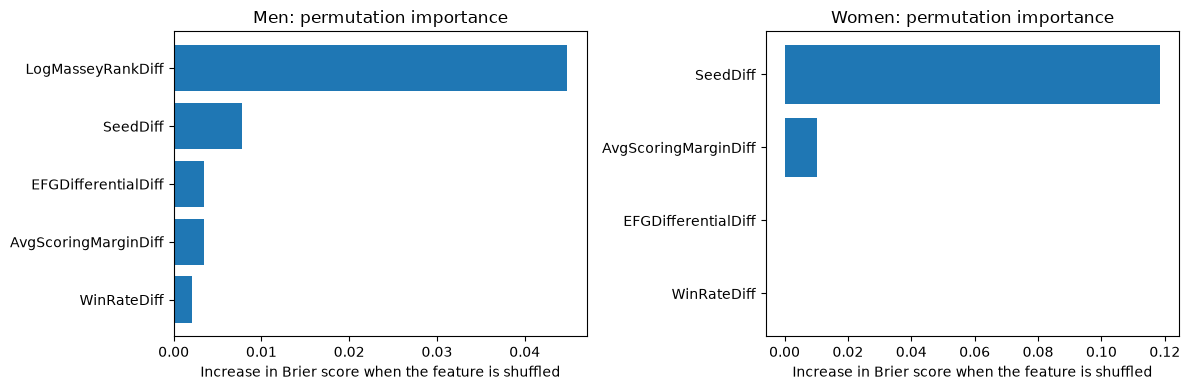

MEN


,Feature,PermutationImportance,BuiltInImportance
0,LogMasseyRankDiff,0.0449,0.4412
1,SeedDiff,0.0078,0.2465
2,EFGDifferentialDiff,0.0035,0.0527
3,AvgScoringMarginDiff,0.0034,0.1779
4,WinRateDiff,0.0021,0.0816


WOMEN


,Feature,PermutationImportance,BuiltInImportance
0,SeedDiff,0.1186,0.7688
1,AvgScoringMarginDiff,0.0104,0.2055
2,EFGDifferentialDiff,0.0002,0.0248
3,WinRateDiff,-0.0000,0.0009


In [53]:
def importance_table(data, features, overrides=None):
    """Which features does the model actually rely on? Trained on seasons <= 2016, judged on 2017-2021."""
    train = data[data["Season"]<=2016]
    valid = data[data["Season"].between(2017,2021)]

    model = make_rf(overrides)
    model.fit(train[features],train[TARGET])                          # TRAINING

    perm = permutation_importance(model, valid[features], valid[TARGET],scoring="neg_brier_score", n_repeats=30, random_state=0, n_jobs=1,)
    return pd.DataFrame({
        "Feature": features,
        "PermutationImportance": perm.importances_mean,
        "BuiltInImportance": model.feature_importances_,
    }).sort_values("PermutationImportance", ascending=False).reset_index(drop=True)

men_importance = importance_table(men_train, MEN_FEATURES, MEN_OVERRIDES)
women_importance = importance_table(women_train, WOMEN_FEATURES, WOMEN_OVERRIDES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, table in zip(axes,["Men", "Women"],[men_importance, women_importance]):
    ordered = table.sort_values("PermutationImportance")
    ax.barh(ordered["Feature"], ordered["PermutationImportance"])
    ax.set_title(f"{name}: permutation importance")
    ax.set_xlabel("Increase in Brier score when the feature is shuffled")
plt.tight_layout()
plt.show()

print("MEN")
display(men_importance.round(4))
print("WOMEN")
display(women_importance.round(4))

Calibration and clipping

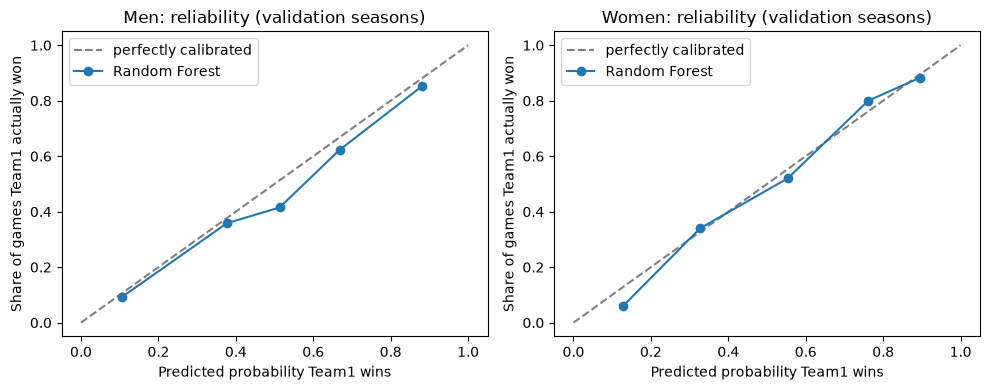

Men - the five groups of games, from lowest to highest prediction


,AvgPredicted,ActualWinRate
0,0.106,0.093
1,0.377,0.358
2,0.513,0.415
3,0.668,0.623
4,0.881,0.852


Women - the five groups of games, from lowest to highest prediction


,AvgPredicted,ActualWinRate
0,0.127,0.059
1,0.327,0.340
2,0.553,0.520
3,0.761,0.800
4,0.894,0.882


,ClipTo,Men,Women
0,"[0.0, 1.0]",0.18369,0.15033
1,"[0.01, 0.99]",0.18362,0.15033
2,"[0.02, 0.98]",0.18356,0.15033
3,"[0.05, 0.95]",0.18347,0.15034


Lowest / highest raw prediction  men: 0.0 0.973 | women: 0.055 0.955


In [54]:
men_cv_scores, men_cv_preds = expanding_window_brier(men_train, MEN_FEATURES, overrides=MEN_OVERRIDES)
women_cv_scores, women_cv_preds = expanding_window_brier(women_train, WOMEN_FEATURES, overrides=WOMEN_OVERRIDES)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, preds in zip(axes, ["Men", "Women"], [men_cv_preds, women_cv_preds]):
    actual_rate, mean_predicted = calibration_curve(preds[TARGET], preds["Pred"], n_bins=5, strategy="quantile")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="perfectly calibrated")
    ax.plot(mean_predicted, actual_rate, marker="o", label="Random Forest")
    ax.set_title(f"{name}: reliability (validation seasons)")
    ax.set_xlabel("Predicted probability Team1 wins")
    ax.set_ylabel("Share of games Team1 actually won")
    ax.legend()
plt.tight_layout()
plt.show()

for name, preds in [("Men", men_cv_preds), ("Women", women_cv_preds)]:
    actual_rate, mean_predicted = calibration_curve(preds[TARGET], preds["Pred"], n_bins=5, strategy="quantile")
    print(name, "- the five groups of games, from lowest to highest prediction")
    display(pd.DataFrame({"AvgPredicted": mean_predicted, "ActualWinRate": actual_rate}).round(3))

clip_rows=[]
for lower in [0.0,0.01,0.02,0.05]:
    clip_rows.append({
        "ClipTo": f"[{lower}, {1 - lower}]",
        "Men": brier_score_loss(men_cv_preds[TARGET], np.clip(men_cv_preds["Pred"], lower, 1 - lower)),
        "Women": brier_score_loss(women_cv_preds[TARGET], np.clip(women_cv_preds["Pred"], lower, 1 - lower)),
    })
display(pd.DataFrame(clip_rows).round(5))
print("Lowest / highest raw prediction  men:", round(men_cv_preds["Pred"].min(), 3), round(men_cv_preds["Pred"].max(), 3),
      "| women:", round(women_cv_preds["Pred"].min(), 3), round(women_cv_preds["Pred"].max(), 3))

Summary Table

In [55]:
summary = pd.DataFrame({
    "Dataset": ["Men", "Women"],
    "Chosen features":[MEN_FEATURES,WOMEN_FEATURES],
    "RF validation Brier":[
        mean_brier(expanding_window_brier(men_train, MEN_FEATURES, overrides=MEN_OVERRIDES)[0]),
        mean_brier(expanding_window_brier(women_train, WOMEN_FEATURES, overrides=WOMEN_OVERRIDES)[0]),],
    "RF holdout 2022-25 Brier": [
        overall_brier(men_hold_final),
        overall_brier(women_hold_final),],
})

display(summary.round(5))

,Dataset,Chosen features,RF validation Brier,RF holdout 2022-25 Brier
0,Men,"[SeedDiff, AvgScoringMarginDiff, WinRateDiff, ...",0.18379,0.20271
1,Women,"[SeedDiff, AvgScoringMarginDiff, WinRateDiff, ...",0.15033,0.15137


Final models

In [56]:
CLIP = 0.02

final_men_rf = make_rf({**MEN_OVERRIDES, "n_estimators": 1000})
final_men_rf.fit(men[MEN_FEATURES], men[TARGET])

final_women_rf = make_rf({**WOMEN_OVERRIDES, "n_estimators": 1000})
final_women_rf.fit(women[WOMEN_FEATURES], women[TARGET])


def predict_matchups(model, matchups, features, clip=CLIP):
    probs = model.predict_proba(matchups[features])[:,1]
    return np.clip(probs, clip, 1-clip)

demo = predict_matchups(final_men_rf, men_holdout.head(5), MEN_FEATURES)
print("Pipeline check:", np.round(demo, 3))
print("Final men's model trained on", len(men), "games.")
print("Final women's model trained on", len(women), "games.")

Pipeline check: [0.588 0.421 0.552 0.507 0.76 ]
Final men's model trained on 1449 games.
Final women's model trained on 961 games.
